In [1]:
# Chit 16: Fashion-MNIST FNN: confusion matrix
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Step 2: Load and prepare Fashion-MNIST
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
image_shape = (28, 28, 1)

In [3]:
# Step 3: Flatten the images
X_train = X_train.reshape(len(X_train), 784)
X_test = X_test.reshape(len(X_test), 784)

In [4]:
# Step 4: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [5]:
# Step 5: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
# Step 6: Prepare and run the model
model.fit(X_train, y_train, epochs=15, batch_size=128, verbose=0)

In [7]:
# Step 7: Predict test images
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

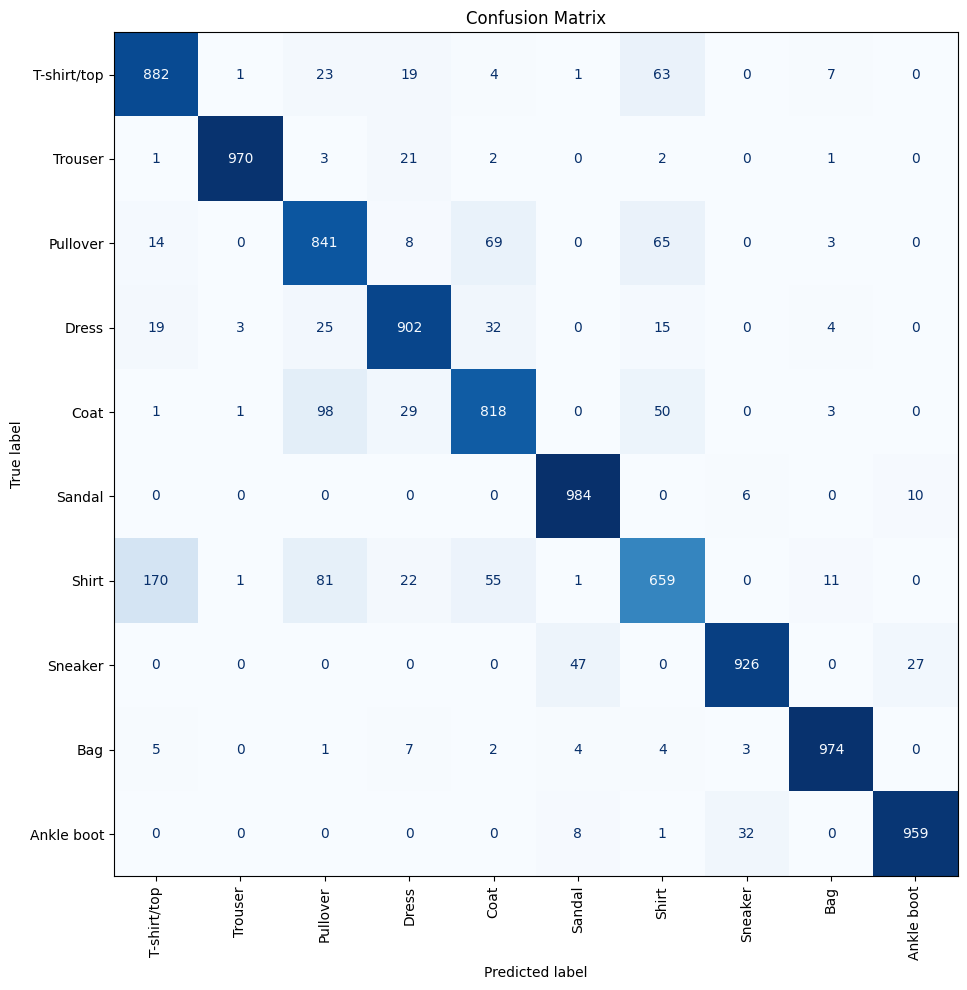

In [8]:
# Step 8: Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, xticks_rotation="vertical", colorbar=False, cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()